# 0. Set up

In [329]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
from scipy.stats import norm, skew

sns.set_theme(context='notebook', style='ticks', palette='bright')
sns.color_palette()

[(0.00784313725490196, 0.24313725490196078, 1.0),
 (1.0, 0.48627450980392156, 0.0),
 (0.10196078431372549, 0.788235294117647, 0.2196078431372549),
 (0.9098039215686274, 0.0, 0.043137254901960784),
 (0.5450980392156862, 0.16862745098039217, 0.8862745098039215),
 (0.6235294117647059, 0.2823529411764706, 0.0),
 (0.9450980392156862, 0.2980392156862745, 0.7568627450980392),
 (0.6392156862745098, 0.6392156862745098, 0.6392156862745098),
 (1.0, 0.7686274509803922, 0.0),
 (0.0, 0.8431372549019608, 1.0)]

In [330]:
# Load datasets
PATH = Path(Path.cwd().parent / 'data')
train = pd.read_csv(PATH / 'train.csv')
test = pd.read_csv(PATH / 'test.csv')

# Save IDs for later
train_ID = train.Id
test_ID = test.Id

# Drop IDs
train = train.drop('Id', axis=1)
test = test.drop('Id', axis=1)

print(f'Train Size: {train.shape}')
print(f'Test Size: {test.shape}')

Train Size: (1460, 80)
Test Size: (1459, 79)


# 1. Data Processing
## 1.1 Outliers

<Axes: xlabel='GrLivArea', ylabel='SalePrice'>

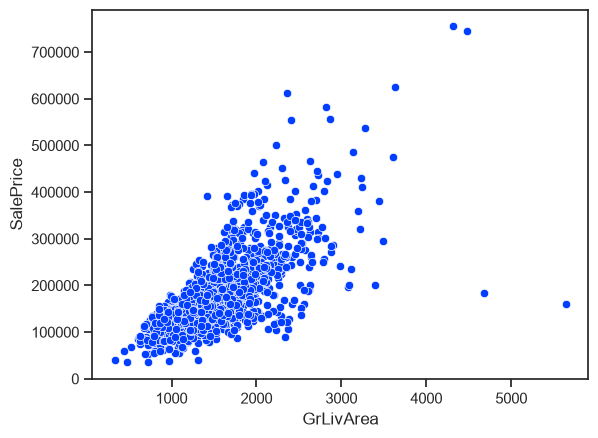

In [331]:
sns.scatterplot(train, x='GrLivArea', y='SalePrice')

In [332]:
# drop outliers
train = train.drop(train[(train.GrLivArea > 4000) & (train.SalePrice < 300000)].index)
train.shape

(1458, 80)

<Axes: xlabel='GrLivArea', ylabel='SalePrice'>

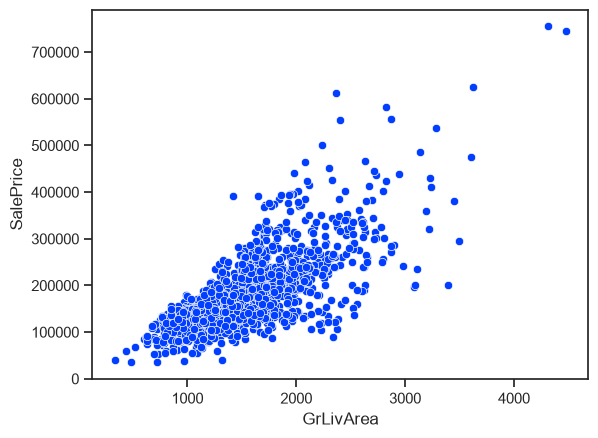

In [333]:
sns.scatterplot(train, x='GrLivArea', y='SalePrice')

## 1.2 Target Variable

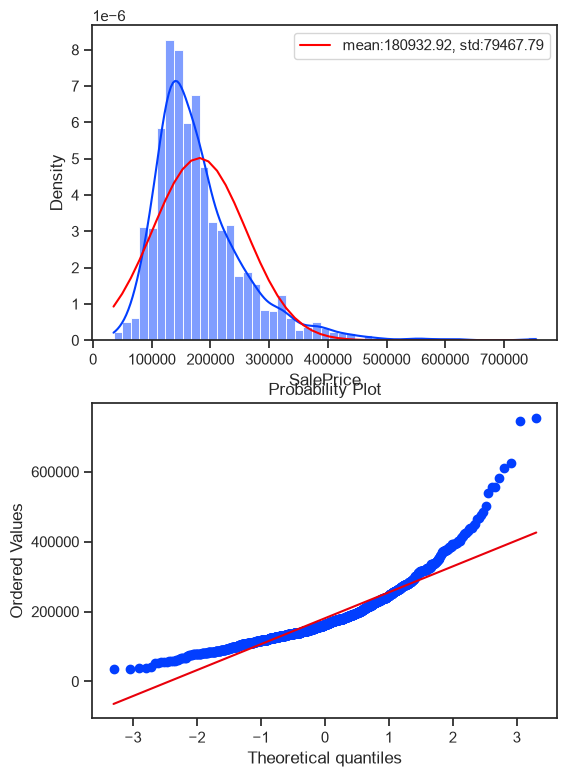

In [334]:
# Distribution of the target variable
fig, ax = plt.subplots(2, 1, figsize=(6, 9))

sns.histplot(train, x='SalePrice', stat='density', kde=True, ax=ax[0])

mu, std = norm.fit(train.SalePrice)
x = np.linspace(min(train.SalePrice), max(train.SalePrice))
pdf = norm.pdf(x, mu, std)

ax[0].plot(x, pdf, color='red', label=f'mean:{mu:.2f}, std:{std:.2f}')
ax[0].legend()

# probability plot
stats.probplot(train.SalePrice, plot=ax[1]);



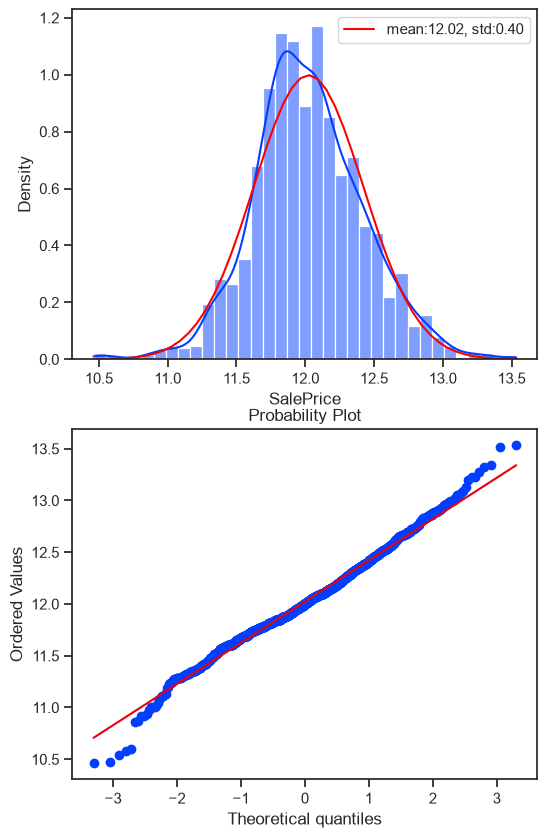

In [335]:
# Normalize SalePrice by log transforming it
train['SalePrice'] = np.log1p(train.SalePrice)

# Redraw the normal distribution plot
fig, ax = plt.subplots(2, 1, figsize=(6, 10))

sns.histplot(train, x='SalePrice', stat='density', kde=True, ax=ax[0])

mu, std = norm.fit(train.SalePrice)
x = np.linspace(min(train.SalePrice), max(train.SalePrice))
pdf = norm.pdf(x, mu, std)

ax[0].plot(x, pdf, color='red', label=f'mean:{mu:.2f}, std:{std:.2f}')
ax[0].legend()

# Probability plot
stats.probplot(train.SalePrice, plot=ax[1]);



## 1.3 Features Engineering

In [336]:
# Concat Train and Test to one DF
all_data = pd.concat([train, test]).reset_index(drop=True)
all_data = all_data.drop('SalePrice', axis=1)
all_data.shape
y_train = train.SalePrice

### 1.3.1 Missing Data

In [337]:
all_data_na = pd.concat((all_data.isna().sum(), all_data.isna().sum()/all_data.isna().count()), axis=1, keys=('Total', 'Percentage'))

all_data_na = all_data_na.sort_values(by='Total', ascending=False)
all_data_na.head(35)

,Total,Percentage
PoolQC,2908,0.996915
MiscFeature,2812,0.964004
Alley,2719,0.932122
Fence,2346,0.804251
MasVnrType,1766,0.605417
FireplaceQu,1420,0.486802
LotFrontage,486,0.166610
GarageYrBlt,159,0.054508
GarageFinish,159,0.054508
GarageQual,159,0.054508


<Axes: xlabel='None', ylabel='Percentage'>

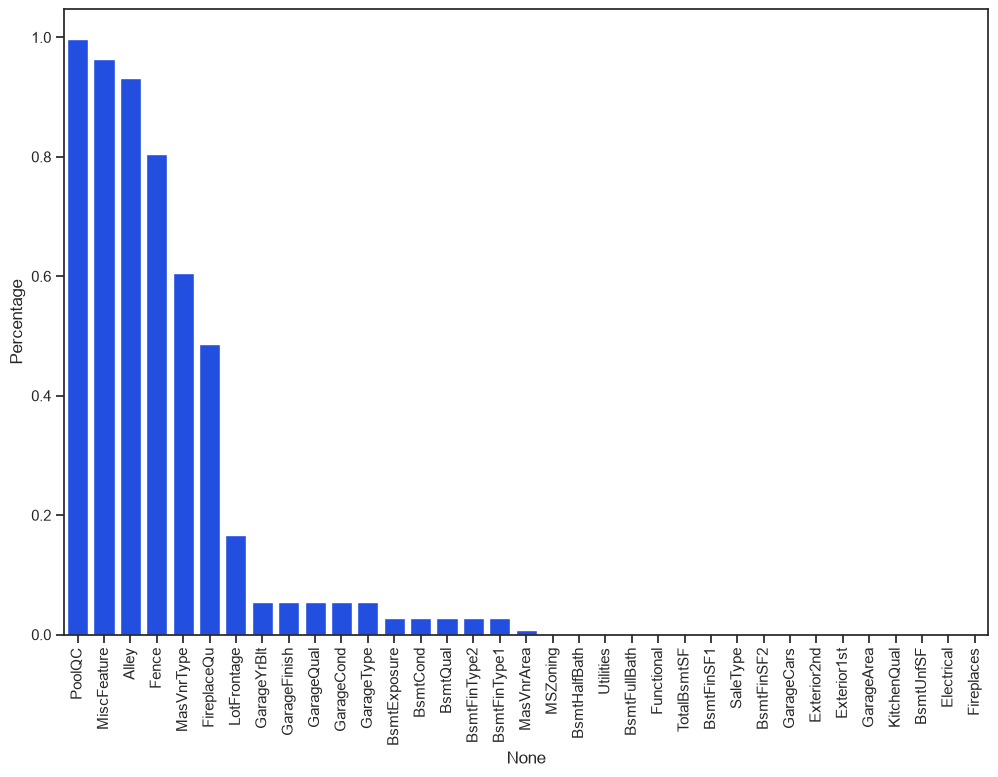

In [338]:
fig, ax = plt.subplots(figsize=(10, 7))
plt.xticks(rotation=90)
plt.tight_layout();
sns.barplot(x=all_data_na.index[:35], y=all_data_na.Percentage[:35])

### 1.3.2 Correlation

<Axes: >

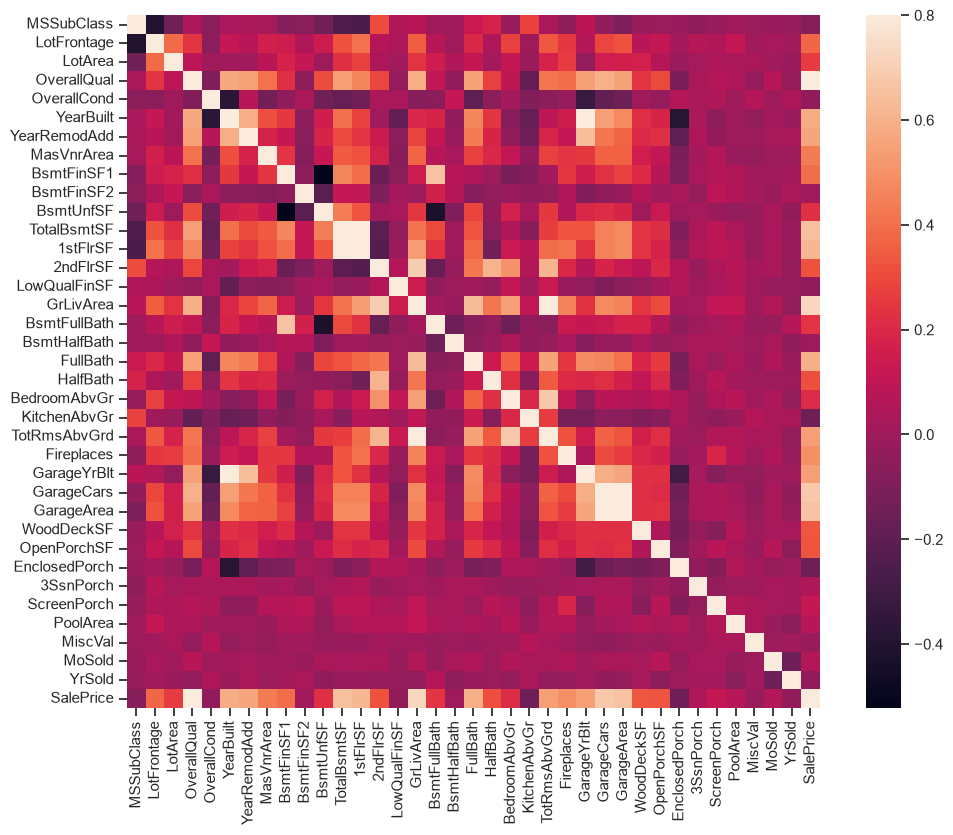

In [339]:
corrmat = train.corr(numeric_only=True)
plt.subplots(figsize=(12, 9))
sns.heatmap(corrmat, vmax=.8, square=True)

### 1.3.3 Null Data Imputation


In [340]:
# PoolQC NA means no pool according to data_description.txt
all_data['PoolQC'] = all_data['PoolQC'].fillna('None')

In [341]:
# MiscFeature NA means None according to data_description.txt
all_data['MiscFeature'] = all_data['MiscFeature'].fillna('None')

In [342]:
# Alley NA means None according to data_description.txt
all_data['Alley'] = all_data['Alley'].fillna('None')

In [343]:
# Fence NA means None according to data_description.txt
all_data['Fence'] = all_data['Fence'].fillna('None')

In [344]:
# MasVnrType NA means None according to data_description.txt
all_data['MasVnrType'] = all_data['MasVnrType'].fillna('None')

In [345]:
# FireplaceQu NA means None according to data_description.txt
all_data['FireplaceQu'] = all_data['FireplaceQu'].fillna('None')

In [346]:
# LotFrontage probably is similar to other properties' in the same neighborhood
# Take mean of the lot frontages in the neighborhood and assign them
all_data['LotFrontage'] = all_data.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))

In [347]:
# All GarageX features have same amount of NA values
# GarageType NA means no garage according to data_description.txt
# Thus, fill NA's according to this info
all_data['GarageArea'] = all_data['GarageArea'].fillna(0)
all_data['GarageCars'] = all_data['GarageCars'].fillna(0)
all_data['GarageCond'] = all_data['GarageCond'].fillna('None')
all_data['GarageFinish'] = all_data['GarageFinish'].fillna('None')
all_data['GarageQual'] = all_data['GarageQual'].fillna('None')
all_data['GarageType'] = all_data['GarageType'].fillna('None')
all_data['GarageYrBlt'] = all_data['GarageYrBlt'].fillna(0)


In [348]:
all_data_na.head(35).index

Index(['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType', 'FireplaceQu',
       'LotFrontage', 'GarageYrBlt', 'GarageFinish', 'GarageQual',
       'GarageCond', 'GarageType', 'BsmtExposure', 'BsmtCond', 'BsmtQual',
       'BsmtFinType2', 'BsmtFinType1', 'MasVnrArea', 'MSZoning',
       'BsmtHalfBath', 'Utilities', 'BsmtFullBath', 'Functional',
       'TotalBsmtSF', 'BsmtFinSF1', 'SaleType', 'BsmtFinSF2', 'GarageCars',
       'Exterior2nd', 'Exterior1st', 'GarageArea', 'KitchenQual', 'BsmtUnfSF',
       'Electrical', 'Fireplaces'],
      dtype='str')

In [349]:
# All BsmtX features probably mean no Basement
basement_cat = ['BsmtExposure', 'BsmtCond', 'BsmtQual', 'BsmtFinType2', 'BsmtFinType1']
basement_num = ['MasVnrArea', 'TotalBsmtSF', 'BsmtFinSF1', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'BsmtHalfBath', 'BsmtFullBath']

for feat in basement_cat:
    all_data[feat] = all_data[feat].fillna('None')
for feat in basement_num:
    all_data[feat] = all_data[feat].fillna(0)

In [350]:
# MSZoning, fillna with the most common zone there
all_data['MSZoning'] = all_data['MSZoning'].fillna(all_data['MSZoning'].mode()[0])

In [351]:
# Utilities 
# For this categorical feature all records are "AllPub", except for one "NoSeWa" and 2 NA . 
# Since the house with 'NoSewa' is in the training set, this feature won't help in predictive modelling. 
# We can then safely remove it.
all_data = all_data.drop('Utilities', axis=1)

In [352]:
# Functional NA probably means typical
all_data['Functional'] = all_data['Functional'].fillna('Typ')

In [353]:
# Electrical NA probably means standard breaker
all_data['Electrical'] = all_data['Electrical'].fillna('SBrkr')

In [354]:
# Erterior2nd, KitchenQual, SaleType, Exterior1st all have 1 NA
# We are good to probably replace it with the most common
features = ['Exterior2nd', 'KitchenQual', 'SaleType', 'Exterior1st']
for feat in features:
    all_data[feat] = all_data[feat].fillna(all_data[feat].mode()[0])

In [355]:
(all_data.isna().sum()).sum() == 0

np.True_

### 1.3.4 More Feature Engineering

In [356]:
# Add total surface area
all_data['TotalSF'] = all_data['TotalBsmtSF'] + all_data['1stFlrSF'] + all_data['2ndFlrSF']

### 1.3.5 Category Encoding

#### 1.3.5.1 Converting Numerical Values that are actually Categorical to Categorical

In [357]:
all_data['MSSubClass'] = all_data['MSSubClass'].apply(str)
all_data['MSSubClass'].head()

0    60
1    20
2    60
3    70
4    60
Name: MSSubClass, dtype: str

#### 1.3.5.2 Label Encoding / One Hot Encoding

In [358]:
categorical_features = all_data.dtypes[all_data.dtypes == 'str'].index.to_list()
print(categorical_features)

['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


In [359]:
ordinal_features = ['ExterQual', 'ExterCond', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC', 'BsmtQual']
binary_nominal_features =['Street', 'CentralAir']   # Includes binary nominal features like 'Street' too
nominal_features = ['MSSubClass', 'MSZoning', 'Alley', 'LotShape', 'LandContour', 'LotConfig', 'LandSlope', 'Neighborhood',
                    'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 
                    'Foundation', 'BsmtFinType1', 'BsmtFinType2',  'Heating', 'Electrical' , 'Functional', 'GarageType', 'PavedDrive', 'Fence', 'MiscFeature',
                    'SaleType','SaleCondition', 'BsmtExposure', 'GarageFinish'
                    ]

In [360]:
set(categorical_features) - set(ordinal_features) - set(nominal_features) - set(binary_nominal_features)

set()

In [361]:
# Label Encoding Ordinal Features
qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}

for c in ordinal_features:
    all_data[c] = all_data[c].map(qual_map)

In [362]:
all_data[ordinal_features]

,ExterQual,ExterCond,BsmtCond,HeatingQC,KitchenQual,FireplaceQu,GarageQual,GarageCond,PoolQC,BsmtQual
0,4,3,3,5,4,0,3,3,0,4
1,3,3,3,5,3,3,3,3,0,4
2,4,3,3,5,4,3,3,3,0,4
3,3,3,4,4,4,4,3,3,0,3
4,4,3,3,5,4,3,3,3,0,4
...,...,...,...,...,...,...,...,...,...,...
2912,3,3,3,4,3,0,0,0,0,3
2913,3,3,3,3,3,0,3,3,0,3
2914,3,3,3,5,3,3,3,3,0,3
2915,3,3,3,3,3,0,0,0,0,4


In [363]:
# Label Encoding binary nominal features
all_data['Street'] = (all_data['Street'] == 'Pave').astype(int)
all_data['CentralAir'] = (all_data['CentralAir'] == 'Y').astype(int)

In [364]:
all_data[['Street', 'CentralAir']].head()

,Street,CentralAir
0,1,1
1,1,1
2,1,1
3,1,1
4,1,1


In [365]:
# One Hot Encoding the nominal features
all_data = pd.get_dummies(all_data, columns=nominal_features, dtype=int)
all_data.shape

(2917, 273)

In [366]:
# Check that nothing text-valued is left over
print(all_data.select_dtypes(exclude='number').columns.tolist())

[]


In [367]:
all_data[ordinal_features].isna().sum().sum() == 0

np.True_

### 1.3.6 Resplit the data

In [368]:
ntrain = train.shape[0]
X_train = all_data[:ntrain]
X_test = all_data[ntrain:]

print(f'X_train shape: {X_train.shape}, X_test shape: {X_test.shape}')

X_train shape: (1458, 273), X_test shape: (1459, 273)


# 2. Predictions

### 2.0.1 Import Libraries

In [369]:
from sklearn.linear_model import ElasticNet, Lasso, BayesianRidge, LassoLarsIC
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.kernel_ridge import KernelRidge
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin, clone 
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.metrics import root_mean_squared_error
import xgboost as xgb
import lightgbm as lgb

### 2.0.2 Define a Cross Val Strategy

In [370]:
SEED = 42

In [371]:
n_folds = 5
kf = KFold(n_folds, shuffle=True, random_state=SEED)

def rmsle_cv(model, X=X_train, y=y_train):
    scores = cross_val_score(model, X, y, cv=kf, scoring='neg_root_mean_squared_error')
    return -scores


## 2.1 Base Models
### 2.1.1 Set Up Models

In [372]:
lasso = make_pipeline(RobustScaler(), Lasso(alpha=0.0005, random_state=SEED))

In [373]:
ENet = make_pipeline(RobustScaler(), ElasticNet(alpha=0.0005, l1_ratio=0.9, random_state=SEED))

In [374]:
KRR = make_pipeline(RobustScaler(), KernelRidge(alpha=0.6, kernel='polynomial', degree=2))

In [375]:
GBoost = GradientBoostingRegressor(n_estimators=3000, learning_rate=.05, max_depth=4, max_features='sqrt',
                                   min_samples_leaf=15, min_samples_split=10, loss='huber', random_state=SEED)

In [376]:
model_xgb = xgb.XGBRegressor()

In [377]:
model_lgb = lgb.LGBMRegressor()

### 2.1.2 Base Model Scores

In [378]:
score = rmsle_cv(lasso)
print(f'Lasso Score: {score.mean():.4f}, {score.std():.4f} ')

Lasso Score: 0.1124, 0.0055 


In [379]:
score = rmsle_cv(ENet)
print(f'ElasticNet Score: {score.mean():.4f}, {score.std():.4f} ')

ElasticNet Score: 0.1125, 0.0056 


In [380]:
score = rmsle_cv(KRR)
print(f'Kernel Ridge Score: {score.mean():.4f}, {score.std():.4f} ')

Kernel Ridge Score: 0.4306, 0.3538 


In [ ]:
score = rmsle_cv(GBoost)
print(f'Gradient Boost Score: {score.mean():.4f}, {score.std():.4f} ')

In [ ]:
score = rmsle_cv(model_xgb)
print(f'XGB Score: {score.mean():.4f}, {score.std():.4f} ')

XGB Score: 0.1328, 0.0100 


In [ ]:
score = rmsle_cv(model_lgb)
print(f'LightGBM Score: {score.mean():.4f}, {score.std():.4f} ')

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007679 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3186
[LightGBM] [Info] Number of data points in the train set: 1166, number of used features: 176
[LightGBM] [Info] Start training from score 12.023362
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004167 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3184
[LightGBM] [Info] Number of data points in the train set: 1166, number of used features: 177
[LightGBM] [Info] Start training from score 12.026498
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM]

# 3. Submission

In [ ]:
model_xgb.fit(X_train, y_train)
y_pred = pd.Series(np.expm1(model_xgb.predict(X_test)))
submission = pd.concat([test_ID, y_pred], axis=1, keys=['Id', 'SalePrice'])
submission = submission.set_index('Id')
submission

,SalePrice
Id,
1461,127266.375000
1462,163807.531250
1463,185982.515625
1464,179394.859375
1465,201918.203125
...,...
2915,79045.835938
2916,79631.546875
2917,176882.937500


In [ ]:
submission.to_csv(PATH / 'submision2.csv')